![Python Banner](../../Image/05_02_meta_learners.png)


# 2.3. Meta-Learners with Continuous Treatments


## Overview

When the treatment variable is continuous — such as a drug dosage, an exposure duration, a price, or a policy intensity — the binary and multi-arm frameworks of the preceding sections no longer apply directly. There is no finite set of contrasts to estimate, and the treatment effect cannot be summarized as a difference between two discrete potential outcomes. Instead, the quantity of interest is a **dose-response function** that describes how the expected outcome, and its rate of change, varies jointly with the treatment level $d$ and the covariate vector $x$.

### Estimands

Two complementary estimands are commonly targeted in the continuous treatment setting.

The **Conditional Average Dose Response (CADR)** function characterizes the full outcome surface as a function of dose:

$$\mu(d, x) = \mathbb{E}[Y(d) \mid X = x]$$

and the treatment effect at dose level $d$ relative to a reference dose $d_0$ (often zero or the observed minimum) is:

$$\tau(d, x) = \mu(d, x) - \mu(d_0, x) = \mathbb{E}[Y(d) - Y(d_0) \mid X = x]$$

This is the natural generalization of the binary CATE: rather than a single scalar effect per unit, we obtain a **curve** — one contrast value for each point on a pre-specified dose grid $\mathcal{D} = \{d_1, d_2, \dots, d_m\}$.

The **Marginal Structural Derivative** (or dose-response slope) targets the local rate of change in the outcome with respect to the treatment:

$$\tau'(d, x) = \frac{\partial}{\partial d} \mathbb{E}[Y(d) \mid X = x]$$

This is useful when the practitioner is interested in marginal effects — whether increasing the dose slightly from its current level improves or worsens outcomes — rather than in cumulative contrasts against a baseline. In practice, $\tau'(d, x)$ is often approximated by finite differences on the estimated CADR surface.

Both estimands require identification via a **generalized unconfoundedness** assumption:

$$Y(d) \perp D \mid X \quad \text{for all } d \in \mathcal{D}$$

along with a **positivity** (or overlap) condition requiring that the generalized propensity score $f(d \mid x)$ — the conditional density of treatment given covariates — is bounded away from zero across the support of $D$:

$$f(d \mid x) > 0 \quad \text{for all } (d, x) \text{ in the support}$$

Violations of positivity are more likely and harder to detect in the continuous setting, since the support of $D$ is infinite-dimensional relative to any finite sample. Overlap diagnostics should therefore be conducted carefully, for example by inspecting the distribution of the generalized propensity score across subgroups.

### The Generalized Propensity Score

In the binary setting, the propensity score $e(x) = P(T=1 \mid X=x)$ is a scalar probability. For continuous treatments, it is replaced by the **generalized propensity score (GPS)**:

$$r(d, x) = f_{D \mid X}(d \mid x)$$

the conditional density of receiving dose $d$ given covariates $x$. The GPS plays the same role as the binary propensity score in balancing covariate distributions and enabling doubly robust estimation, but its estimation is substantially more demanding. Common approaches include:

- **Parametric GPS**: Assume $D \mid X \sim \mathcal{N}(\hat{m}(x), \hat{\sigma}^2)$ where $\hat{m}(x)$ is a regression of $D$ on $X$. The GPS is then evaluated as the normal density at the observed dose.
- **Nonparametric GPS**: Use kernel density estimation or normalizing flows conditioned on $X$ to estimate $f(d \mid x)$ without distributional assumptions.
- **Residual-based GPS**: In the R-Learner, the GPS enters implicitly through the treatment residual $D - \hat{m}(X)$, avoiding the need to estimate the full conditional density.

Misspecification of the GPS can introduce substantial bias into propensity-weighted and doubly robust estimators, and this risk is heightened in the continuous case relative to binary treatments.

### Adapting Meta-Learner Variants to Continuous Treatments

#### S-Learner

The S-Learner fits a single outcome model $\hat{\mu}(x, d)$ on the full sample, treating the continuous dose $D$ as an additional continuous feature alongside $X$:

$$\hat{\tau}(d, x) = \hat{\mu}(x, d) - \hat{\mu}(x, d_0)$$

The dose-response curve is recovered by evaluating $\hat{\mu}(x, \cdot)$ on the dose grid $\mathcal{D}$ at any covariate value of interest. This is the most straightforward extension and imposes no particular structure on the dose-response shape, relying entirely on the base learner to capture the joint $(X, D)$ surface. Flexible base learners such as gradient boosting or neural networks can represent nonlinear and non-monotone dose-response relationships naturally. The key limitation is the same as in the binary case: if the base learner imposes strong smoothness or regularization in the $D$ direction, the estimated dose-response curve may be overly flat and fail to capture meaningful heterogeneity.

#### T-Learner

The T-Learner generalizes to the continuous setting by **discretizing** the dose into $m$ bins or grid points $\{d_1, \dots, d_m\}$ and fitting a separate outcome model $\hat{\mu}_j(x)$ for each bin $j$:

$$\hat{\tau}(d_j, x) = \hat{\mu}_j(x) - \hat{\mu}_0(x)$$

where $\hat{\mu}_0(x)$ corresponds to the reference dose bin. This approach is intuitive but has significant practical drawbacks. The choice of binning scheme is arbitrary and can meaningfully affect results. Fine grids produce sparse bins, each with few observations, leading to high-variance arm-specific models — essentially the same sparsity problem that affects multi-arm T-Learners, but now potentially at much larger scale. For this reason, the T-Learner is generally the least preferred meta-learner for continuous treatments unless the dose variable is naturally near-discrete in its distribution.

#### X-Learner

The X-Learner can be adapted to continuous treatments by applying the cross-fitting logic **locally** on the dose grid: for each grid point $d_j$, units near $d_j$ and units at the reference dose $d_0$ are selected, and the binary X-Learner pipeline is run on this local subsample using an arm-specific propensity model. The resulting local estimates are then assembled into a dose-response curve. This approach inherits the X-Learner's efficiency advantages under imbalance — which is common in continuous treatment settings where the dose distribution may be concentrated in certain regions — but introduces sensitivity to the bandwidth or neighborhood definition used to select units near each grid point.

#### R-Learner

The R-Learner is particularly well-suited to the continuous treatment setting and is the method implemented in `r_learner_continuous()` in **PyCausalML**. It extends Robinson's (1988) partial linear residualization to the continuous case by orthogonalizing both the outcome and the treatment against their respective conditional expectations:

1. Estimate nuisance functions:
   - $\hat{m}(x) = \mathbb{E}[D \mid X = x]$ (dose regression on covariates)
   - $\hat{\mu}(x) = \mathbb{E}[Y \mid X = x]$ (outcome regression on covariates, marginalizing over dose)

2. Compute residuals:
   - Outcome residual: $\tilde{Y}_i = Y_i - \hat{\mu}(X_i)$
   - Treatment residual: $\tilde{D}_i = D_i - \hat{m}(X_i)$

3. Estimate $\tau(d, x)$ by solving:

$$\min_{\tau} \mathbb{E}\left[ \left( \tilde{Y}_i - \tau(D_i, X_i) \cdot \tilde{D}_i \right)^2 \right]$$

The orthogonalization ensures that errors in the nuisance estimates $\hat{m}(x)$ and $\hat{\mu}(x)$ enter the CATE estimation problem only at second order, providing robustness to moderate nuisance misspecification. Under regularity conditions, the R-Learner achieves near-oracle convergence rates for $\tau(d, x)$ (Nie & Wager, 2021). In `r_learner_continuous()`, the final step is implemented by evaluating the fitted $\hat{\tau}(\cdot, x)$ on the dose grid $\mathcal{D}$, yielding a discretized dose-response curve for each unit or covariate profile.

#### DR-Learner

The DR-Learner generalizes to continuous treatments by constructing **doubly robust pseudo-outcomes** using the generalized propensity score. For a contrast at dose level $d$ versus reference $d_0$, the AIPW-style pseudo-outcome for unit $i$ is:

$$\hat{\phi}_i(d) = \frac{\mathbf{1}[D_i \approx d]}{r(d, X_i)} \left(Y_i - \hat{\mu}(d, X_i)\right) - \frac{\mathbf{1}[D_i \approx d_0]}{r(d_0, X_i)} \left(Y_i - \hat{\mu}(d_0, X_i)\right) + \hat{\mu}(d, X_i) - \hat{\mu}(d_0, X_i)$$

where $r(d, x) = f(d \mid x)$ is the generalized propensity score and the indicator $\mathbf{1}[D_i \approx d]$ selects units with doses in a neighborhood of $d$. Regressing $\hat{\phi}_i(d)$ on $X_i$ for each grid point $d \in \mathcal{D}$ yields the DR-Learner dose-response estimate. The doubly robust property holds pointwise on the grid: at each dose level $d$, the estimate is consistent if either the outcome model $\hat{\mu}(d, x)$ or the GPS $r(d, x)$ is correctly specified. However, the localization step introduces a bandwidth choice, and the pseudo-outcome construction is sensitive to extreme GPS values — a risk that is heightened in the continuous setting because near-zero densities can occur in any region of the dose support.

### Single-Vector Summaries with `treatment_type = "continuous"`

In many applied settings, the practitioner does not need the full dose-response curve. Instead, a **single-vector CATE summary** — one scalar effect estimate per unit — is sufficient, typically representing the effect of moving from the observed dose to a target dose, or the local slope of the dose-response at the observed dose. The meta-learners in **PyCausalML** with `treatment_type = "continuous"` are designed for this use case. Rather than evaluating $\hat{\tau}(d, x)$ on a full grid, they return:

$$\hat{\tau}_i = \hat{\tau}(D_i^*, X_i)$$

where $D_i^*$ is a user-specified target dose (e.g., the population mean dose, the maximum tolerated dose, or a policy-relevant threshold). This produces a unit-level treatment effect vector of the same form as in the binary CATE setting, enabling the same downstream analyses — effect heterogeneity visualization, policy targeting, subgroup discovery — without committing to a full dose-response curve estimation.

### Practical Considerations

Continuous treatment settings require additional care relative to binary and multi-arm settings along several dimensions:

- **Dose grid selection**: The resolution of $\mathcal{D}$ involves a bias-variance tradeoff. Fine grids yield smoother curves but thinner local samples; coarser grids are more stable but may obscure nonlinearities. Adaptive grids based on the observed dose distribution are often preferable to uniform spacing.
- **GPS estimation quality**: The generalized propensity score is harder to estimate well than a binary propensity score, and GPS misspecification propagates into weighted and doubly robust estimators. Residual diagnostics — checking whether $\tilde{D}_i = D_i - \hat{m}(X_i)$ is approximately uncorrelated with $X_i$ after adjustment — are a useful sanity check.
- **Extrapolation risk**: Unlike binary treatments where predictions are made at $W \in \{0, 1\}$, continuous treatment estimators must extrapolate $\hat{\mu}(d, x)$ to dose values not observed near a given covariate profile. This is particularly problematic at the tails of the dose distribution and in regions of thin overlap.
- **Monotonicity and shape constraints**: When domain knowledge supports a monotone or concave dose-response relationship, incorporating shape constraints into the base learner can substantially reduce estimation variance at the cost of flexibility.


## Setup

This notebook uses **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml`).

`fit(X, treatment, y)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
try:
    import pycausalml  # noqa: F401
    import causaldata  # noqa: F401
    import matplotlib  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
        "statsmodels", "causaldata",
    ])
print("PyCausalML ready.")


PyCausalML ready.


## Part A: Meta-learners with synthetic data

We simulate a **continuous** treatment and a smooth dose–response surface so we can compare estimates to a known benchmark.

### Data Generation for Continuous Treatment


In [2]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from pycausalml import (
    DRLearner,
    DomainAdaptationLearner,
    LinearDML,
    RLearner,
    SLearner,
    SparseLinearDML,
    TLearner,
    XLearner,
    explain_cate,
    synthetic_data,
)
from pycausalml.data import make_multiarm_data
from pycausalml.double_machine_learning import CausalForestDML, PartiallyLinearDML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
N_EST = 25
print("Imported PyCausalML")

rng = np.random.default_rng(123)
n, p = 1000, 6
X = rng.normal(size=(n, p))
dose = np.clip(rng.normal(1.4 + 0.35 * X[:, 0], 0.55, size=n), 0.05, 4.0)
modifier = 1.0 + 0.45 * X[:, 0]
# Marginal slope (1.15 - 0.30 * d) * modifier. Outcome is the integral plus noise.
y = (
    0.5 * X[:, 1]
    + dose * modifier * (1.15 - 0.15 * dose)
    + rng.normal(scale=0.45, size=n)
)
true_slope = (1.15 - 0.30 * dose) * modifier
names = [f"X{i+1}" for i in range(p)]
grid = np.linspace(np.quantile(dose, 0.08), np.quantile(dose, 0.92), 11)
print(X.shape, "dose mean", round(float(dose.mean()), 3))


Imported PyCausalML
(1000, 6) dose mean 1.411


### Estimand: Conditional Average Dose Response (CADR)

For continuous treatment $D$ (e.g., dosage), we estimate:

$$\tau(d, x) = \frac{\partial}{\partial d} \mathbb{E}[Y(d) \mid X = x]$$

This is the **marginal effect** of an infinitesimal dose increase at level $d$ for units with covariates $x$.

### Generalized R-Learner for Continuous Treatments

Extends Robinson transformation to continuous treatments using **kernel smoothing**. The implementation lives in **PyCausalML** as `r_learner_continuous()` (cross-fitted `learner="rf"` nuisances and local weighted `lm`, with cross-fitted gradient-boosting nuisances and a local weighted slope):


### Average Dose-Response Curve


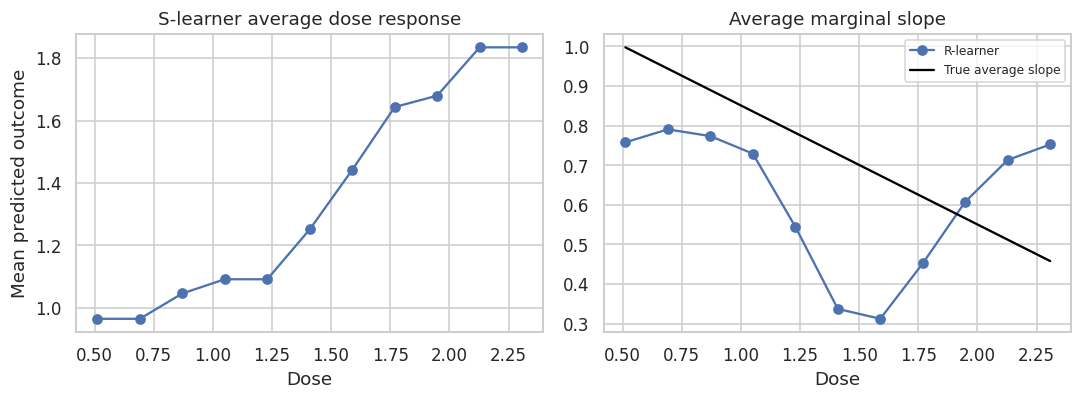

In [3]:
from sklearn.ensemble import GradientBoostingRegressor

mu = GradientBoostingRegressor(n_estimators=N_EST, max_depth=2, random_state=0)
mu.fit(np.column_stack([X, dose]), y)
level = [float(mu.predict(np.column_stack([X, np.full(len(X), d)])).mean()) for d in grid]

m_y = np.zeros(len(y))
m_d = np.zeros(len(y))
rng_fold = np.random.default_rng(0)
fold = rng_fold.integers(0, 2, size=len(y))
for k in (0, 1):
    tr, te = fold != k, fold == k
    fy = GradientBoostingRegressor(n_estimators=N_EST, max_depth=2, random_state=0).fit(X[tr], y[tr])
    fd = GradientBoostingRegressor(n_estimators=N_EST, max_depth=2, random_state=1).fit(X[tr], dose[tr])
    m_y[te] = fy.predict(X[te])
    m_d[te] = fd.predict(X[te])
y_res, d_res = y - m_y, dose - m_d
bw = 1.06 * np.std(dose) * len(dose) ** (-0.2)

def local_slope(mask=None):
    dd = dose if mask is None else dose[mask]
    yr = y_res if mask is None else y_res[mask]
    dr = d_res if mask is None else d_res[mask]
    out = []
    for g in grid:
        wt = np.exp(-0.5 * ((dd - g) / bw) ** 2)
        out.append(float(np.sum(wt * dr * yr) / np.sum(wt * dr ** 2)))
    return np.asarray(out)

slope_hat = local_slope()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(grid, level, marker="o")
axes[0].set_title("S-learner average dose response")
axes[0].set_xlabel("Dose")
axes[0].set_ylabel("Mean predicted outcome")
axes[1].plot(grid, slope_hat, marker="o", label="R-learner")
axes[1].plot(grid, [((1.15 - 0.30 * g) * modifier).mean() for g in grid], color="black", label="True average slope")
axes[1].set_title("Average marginal slope")
axes[1].set_xlabel("Dose")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


### Heterogeneous Dose-Response: Effect Modification

Visualize how dose-response varies by key covariate (X1):


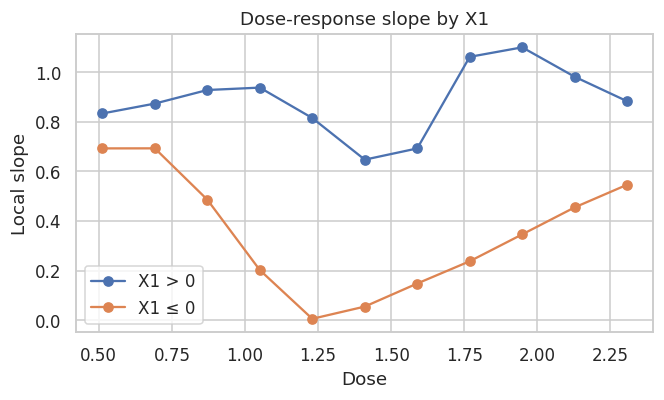

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for mask, label in ((X[:, 0] > 0, "X1 > 0"), (X[:, 0] <= 0, "X1 ≤ 0")):
    ax.plot(grid, local_slope(mask), marker="o", label=label)
ax.set_xlabel("Dose")
ax.set_ylabel("Local slope")
ax.set_title("Dose-response slope by X1")
ax.legend()
fig.tight_layout()
plt.show()


### Native S/T/X/R/DR with `a continuous dose` (synthetic)

**PyCausalML** now accepts **continuous** `treatment` for `SLearner`, `TLearner`, `XLearner`, `RLearner`, and `DRLearner` via `a continuous dose`. This is **not** the same object as **`r_learner_continuous()`** (which returns a **dose grid** $\times$ units surface for CADR): here you get a **single** $\hat{\tau}(X)$ vector per specification (e.g., S-learner contrast $\mu(X,d_1)-\mu(X,d_0)$ at training quartiles of $D$; T/X high-vs-low dose at the median; R-learner Robinson partial effect; DR continuous pseudo-outcome). The chunk below is a minimal sanity check on the same simulated data as above.


In [5]:
d0, d1 = np.quantile(dose, [0.25, 0.75])
s_mu = GradientBoostingRegressor(n_estimators=N_EST, max_depth=2, random_state=2)
s_mu.fit(np.column_stack([X, dose]), y)
s_contrast = s_mu.predict(np.column_stack([X, np.full(len(X), d1)])) - s_mu.predict(np.column_stack([X, np.full(len(X), d0)]))
high = (dose > np.median(dose)).astype(int)
native_rows = [{"learner": "S contrast (q75-q25)", "mean": float(s_contrast.mean())}]
for label, cls in (("T median split", TLearner), ("X median split", XLearner), ("DR median split", DRLearner)):
    model = cls(learner="gbr", n_estimators=N_EST, random_state=2)
    model.fit(X, high, y, feature_names=names)
    native_rows.append({"learner": label, "mean": float(np.mean(model.predict(X)))})
plr = PartiallyLinearDML(discrete_treatment=False, model_y="gbr", n_estimators=N_EST, random_state=2)
plr.fit(X, dose, y, feature_names=names)
native_rows.append({"learner": "Partially linear DML slope", "mean": float(plr.effect())})
print(pd.DataFrame(native_rows).round(3).to_string(index=False))
print("True mean slope", round(float(true_slope.mean()), 3))


                   learner  mean
      S contrast (q75-q25) 0.597
            T median split 0.849
            X median split 0.695
           DR median split 0.720
Partially linear DML slope 0.699
True mean slope 0.683


### Diagnostics & Validation Protocol

Diagnostics help ensure that dose-response estimates are not driven by lack of overlap, covariate imbalance, or miscalibration. Below we implement overlap checks, balance assessment before/after weighting, and a CATE calibration plot.

#### Overlap Diagnostics

For continuous treatments, **overlap** means that the conditional support of $D$ given $X$ has sufficient density across the dose range we care about. We check the marginal distribution of $D$ and the distribution of the conditional expectation $E[D|X]$ (estimated via a regression of $D$ on $X$) to assess common support.


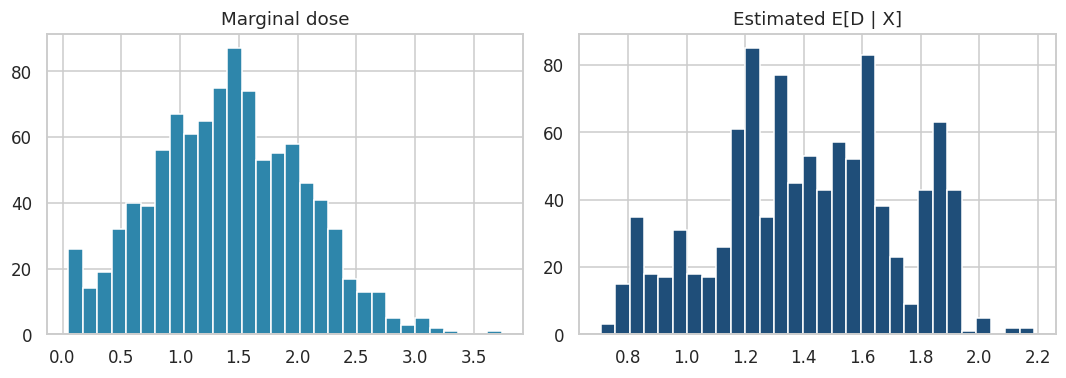

quartile    Q1     Q2     Q3     Q4
covariate                          
X1         0.0  0.400  0.849  1.312
X2         0.0 -0.025  0.046  0.003
X3         0.0  0.081  0.018  0.058
X4         0.0  0.120  0.072  0.005
X5         0.0 -0.103 -0.126  0.014
X6         0.0  0.032 -0.031  0.074


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(dose, bins=30, color="#2E86AB")
axes[0].set_title("Marginal dose")
axes[1].hist(m_d, bins=30, color="#1F4E79")
axes[1].set_title("Estimated E[D | X]")
fig.tight_layout()
plt.show()

quartiles = pd.qcut(dose, 4, labels=["Q1", "Q2", "Q3", "Q4"])
rows = []
for q in ["Q1", "Q2", "Q3", "Q4"]:
    mask = quartiles == q
    ref = quartiles == "Q1"
    for j, name in enumerate(names):
        rows.append({
            "quartile": q,
            "covariate": name,
            "smd_vs_q1": float((X[mask, j].mean() - X[ref, j].mean()) / (X[:, j].std() + 1e-8)),
        })
print(pd.DataFrame(rows).pivot(index="covariate", columns="quartile", values="smd_vs_q1").round(3))


Interpretation: substantial overlap across covariate strata (e.g., E[D|X] distributions by X1 quartile) supports estimation of dose-response over the observed dose range; narrow or separated supports suggest limited overlap and cautious interpretation.

#### Balance Assessment (Before/After Weighting)

We stratify units by dose quartiles and assess **standardized mean differences (SMD)** of covariates across strata. We then compute **stabilized inverse probability of treatment weights** (IPTW) for continuous $D$ using a normal approximation: $w_i = f(D_i) / f(D_i|X_i)$, with $f(D|X)$ from $D|X \sim N(\hat{e}(X), \hat{\sigma}^2)$, and reassess balance after weighting.


#### CATE Calibration Plot

We bin units by their **predicted marginal effect** at a reference dose (median dose) and plot mean predicted effect vs. mean observed outcome (residualized by baseline) in each bin. A well-calibrated estimator should show a positive alignment between predicted effect and realized outcomes.


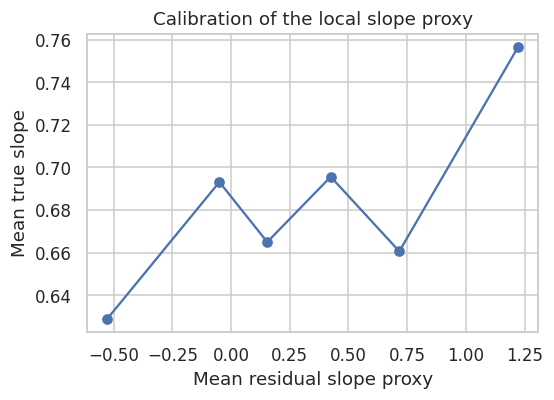

In [7]:
ref = float(np.median(dose))
pred_at_ref = np.array([
    local_slope()[np.argmin(np.abs(grid - ref))]
] * len(X))
# unit-level slope proxy: residual ratio, shrunk
unit_slope = y_res * d_res / (d_res ** 2 + 0.15)
bins = pd.qcut(unit_slope, 6, duplicates="drop")
tab = pd.DataFrame({"pred": unit_slope, "actual": true_slope, "bin": bins}).groupby("bin", observed=True).mean()
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.plot(tab.pred, tab.actual, marker="o")
ax.set_xlabel("Mean residual slope proxy")
ax.set_ylabel("Mean true slope")
ax.set_title("Calibration of the local slope proxy")
fig.tight_layout()
plt.show()


### Decision Framework: Which Meta-Learner to Use?

For **continuous treatments**, the choice of approach depends on data structure and goals:

| Criterion | Recommendation |
|-----------|----------------|
| **Target** | Full curve $\tau(d,x)$ on a grid → `r_learner_continuous()`. Single-vector heterogeneous “effects” with continuous $D$ in **PyCausalML** → `SLearner` / `TLearner` / `XLearner` / `RLearner` / `DRLearner` with `treatment_type = "continuous"` (see help text for each estimand). |
| **Overlap** | Ensure sufficient density of $D$ across $X$; trim or restrict to common support if needed. |
| **Curvature** | If effect is linear in $d$ → local linear R-Learner or parametric DR model; if nonlinear → kernel smoothing, splines, or generalized random forests. |
| **Bandwidth** | Use cross-validation to choose bandwidth for kernel weights; Silverman-type rules are a starting point. |
| **Alternatives** | **Generalized random forests** (generalized random forests) for continuous treatment; **double ML** with series expansion in $d$; **causal BART** with continuous treatment. |

Use the **R-Learner** when you want a debiased, flexible estimator that leverages ML for nuisances and residualization; use **GRF** or **BART** when you prefer a single forest that directly targets the dose-response.

## Part B: Use case — NMES (`nmes_data` from `this tutorial (`data/nmes_data.csv`)`)

**`nmes_data`** comes from the **1987 National Medical Expenditure Survey (NMES)** and is bundled in **`this tutorial (`data/nmes_data.csv`)`** (`data/nmes_data.csv`). It is widely used for **continuous treatment** / dose-response methods (e.g., Imai & van Dyk, 2004). The extract has **9,708** observations and **12** variables (complete cases in the packaged version).

| Role | Variable | Description |
|------|-----------|-------------|
| **Outcome** | `TOTALEXP` | Total annual medical expenditures (USD) |
| **Treatment** | `packyears` | Pack-years: (cigarettes per day / 20) × years smoked |
| **Covariates** | `AGESMOKE` | Age when started smoking |
| | `LASTAGE` | Age at last interview |
| | `MALE` | Sex (indicator) |
| | `RACE3` | Race (coded) |
| | `educate` | Education |
| | `marital` | Marital status |
| | `SREGION` | Census region |
| | `POVSTALB` | Poverty status |
| | `beltuse` | Seat belt use |
| | `HSQACCWT` | Sampling weight (include as covariate here for simplicity; full survey inference would use design-based weights) |

Inference is only as credible as **unconfoundedness** and **overlap** over the support of `packyears`.

### Explore treatment and outcome


### Prepare analysis data and fit generalized R-learner

We map **`TOTALEXP` $\to$ `Y`**, **`packyears` $\to$ `D`**, and use the covariates above. The **dose grid** spans the 5th–95th percentiles of `packyears` to limit extrapolation.


(9708, 12)
       packyears   TOTALEXP
count    9708.00    9708.00
mean       24.48    2042.01
std        24.30    6410.79
min         0.05       0.00
25%         6.60      90.00
50%        17.25     406.09
75%        34.50    1350.33
max       216.00  175095.97


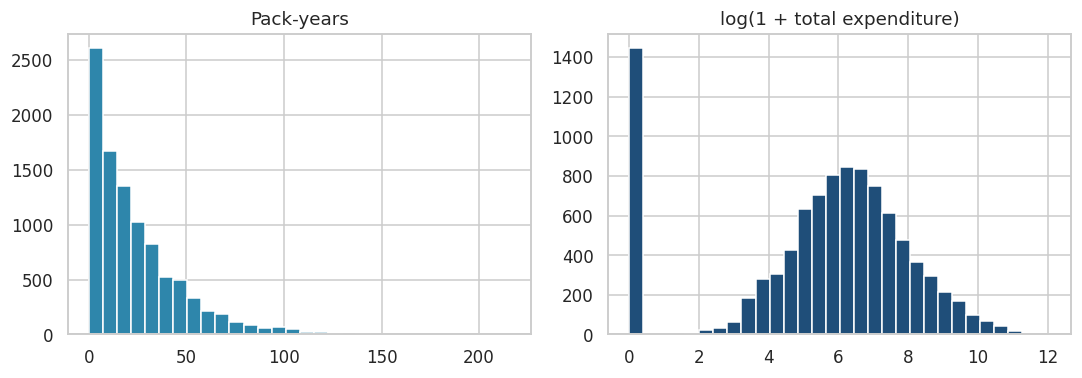

NMES subsample 1200 covariates ['AGESMOKE', 'LASTAGE', 'MALE', 'RACE3', 'beltuse', 'educate', 'marital', 'SREGION', 'POVSTALB', 'HSQACCWT']


In [8]:
def tutorial_file(name: str):
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        path = cand / "Tutorials" / "05_02_Meta_Learners" / "data" / name
        if path.is_file():
            return path
    raise FileNotFoundError(name)

nmes = pd.read_csv(tutorial_file("nmes_data.csv"))
print(nmes.shape)
print(nmes[["packyears", "TOTALEXP"]].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(nmes["packyears"], bins=30, color="#2E86AB")
axes[0].set_title("Pack-years")
axes[1].hist(np.log1p(nmes["TOTALEXP"]), bins=30, color="#1F4E79")
axes[1].set_title("log(1 + total expenditure)")
fig.tight_layout()
plt.show()

rng = np.random.default_rng(4)
take = rng.choice(len(nmes), size=1200, replace=False)
sub = nmes.iloc[take].reset_index(drop=True)
covars = [c for c in sub.columns if c not in ("TOTALEXP", "packyears")]
Xn = sub[covars].to_numpy(dtype=float)
dn = sub["packyears"].to_numpy(dtype=float)
yn = np.log1p(sub["TOTALEXP"].to_numpy(dtype=float))
nmes_names = covars
grid_n = np.linspace(np.quantile(dn, 0.05), np.quantile(dn, 0.95), 9)
mu_n = GradientBoostingRegressor(n_estimators=N_EST, max_depth=2, random_state=4)
mu_n.fit(np.column_stack([Xn, dn]), yn)
level_n = [float(mu_n.predict(np.column_stack([Xn, np.full(len(Xn), d)])).mean()) for d in grid_n]
print("NMES subsample", len(sub), "covariates", covars)


### Average estimated local slope vs pack-years (NMES)


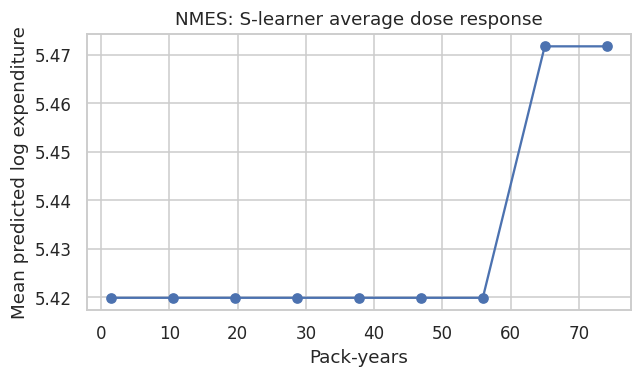

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(grid_n, level_n, marker="o")
ax.set_xlabel("Pack-years")
ax.set_ylabel("Mean predicted log expenditure")
ax.set_title("NMES: S-learner average dose response")
fig.tight_layout()
plt.show()


### Quick overlap check (continuous treatment)

We plot the **marginal distribution of** `packyears` and the distribution of **$\hat{E}[D \mid X]$** (random forest) by sex, as a simple overlap diagnostic.


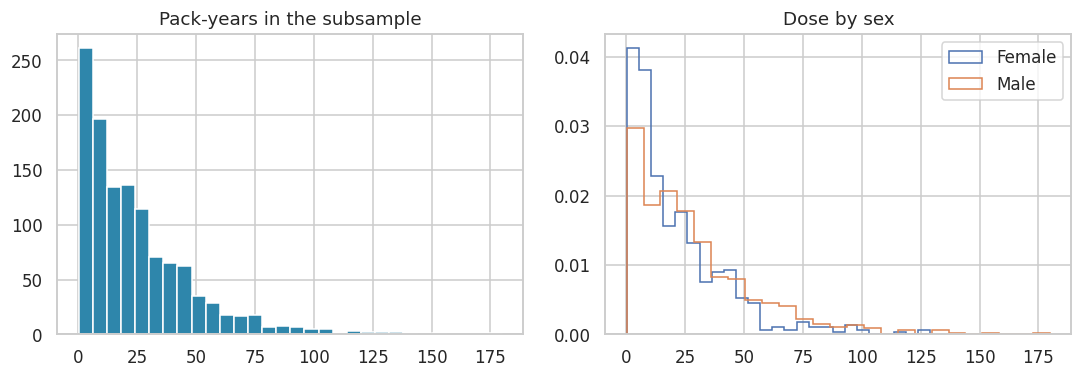

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(dn, bins=30, color="#2E86AB")
axes[0].set_title("Pack-years in the subsample")
male = sub["MALE"].to_numpy()
axes[1].hist(dn[male == 0], bins=25, density=True, histtype="step", label="Female")
axes[1].hist(dn[male == 1], bins=25, density=True, histtype="step", label="Male")
axes[1].set_title("Dose by sex")
axes[1].legend()
fig.tight_layout()
plt.show()


### Meta-learners on NMES: continuous `packyears` and binary median split

For compute time when rendering, we fit meta-learners on a **random subsample** of up to **3,000** rows (the **`r_learner_continuous()`** fit above still uses **all** complete cases).

**1. Native continuous treatment.** Pass **`packyears`** as `treatment` with `treatment_type = "continuous"`. **S-Learner** contrasts predicted outcome at the **25th vs. 75th percentile** of training $D$ (override with `dose_values = c(d0, d1)`). **T- / X-Learner** use the **sample median** of $D$ as high-vs-low split (override with `dose_split`). **R-Learner** uses **Robinson-style** $\mathbb{E}[Y|X]$ and $\mathbb{E}[D|X]$ nuisances. **DR-Learner** uses a **continuous** cross-fitted pseudo-outcome (see package documentation). Covariates **exclude** raw `packyears` so dose enters only through `treatment`.

**2. Binary median split.** For a classic **ATE** of high vs. low exposure and for **SHAP** below, we also fit **binary** learners on

$$W_i = \mathbf{1}\{\texttt{packyears}_i > \mathrm{median}(\texttt{packyears})\}.$$

We still **do not** put raw `packyears` in $X$ when using $W$ (overlap).


In [11]:
high = (dn > np.median(dn)).astype(int)
rows = []
stored = {}
for label, cls in (("S", SLearner), ("T", TLearner), ("X", XLearner), ("R", RLearner), ("DR", DRLearner)):
    model = cls(learner="gbr", n_estimators=N_EST, random_state=4)
    model.fit(Xn, high, yn, feature_names=nmes_names)
    stored[label] = model
    rows.append({"learner": f"{label} high vs low pack-years", "mean_cate": float(np.mean(model.predict(Xn)))})
plr_n = PartiallyLinearDML(discrete_treatment=False, model_y="gbr", n_estimators=N_EST, random_state=4)
plr_n.fit(Xn, dn, yn, feature_names=nmes_names)
rows.append({"learner": "Partially linear DML (per pack-year)", "mean_cate": float(plr_n.effect())})
print(pd.DataFrame(rows).round(3).to_string(index=False))


                             learner  mean_cate
            S high vs low pack-years      0.000
            T high vs low pack-years      0.040
            X high vs low pack-years     -0.042
            R high vs low pack-years     -0.110
           DR high vs low pack-years     -0.069
Partially linear DML (per pack-year)      0.000


The **mean predicted** column averages $\hat{\tau}(X)$ from `predict()`; **`ate_plugin`** uses `estimate_ate()`’s internal variance formulas (continuous rows use high-vs-low-$D$ logic where applicable). Interpret **S** as a **dose contrast** at training quartiles, **T/X** as **above-median vs. below**, **R** as a **Robinson-type** effect, and **DR** as the **continuous DR** CATE surface aggregated to a mean—comparability across columns is limited.


### Use case: Double machine learning on NMES (DML)

We reuse the **same subsample** (`X_meta`, `d_meta` = `packyears`, `y_meta` = `TOTALEXP`) and fit **partially linear DML** with random forests nuisances: **`LinearDML`** (OLS final stage on residual interactions), **`SparseLinearDML`** (Lasso final stage), and **`CausalForestDML`** (**`a causal forest`** on residuals). All three target **$\hat{\theta}(X)$** in $\tilde{Y} \approx \tilde{D}\cdot\theta(X)$ with continuous $\tilde{D}$ (see ``pycausalml.double_machine_learning``). There is **no ground-truth CATE** on NMES, so we compare **(i)** **ATE** with a large-sample normal CI, **(ii)** **holdout RMSE** of the cross-fitted **$\hat{\mathbb{E}}[Y\mid X]$** on a 30% test split (models refit on 70% train only), and **(iii)** **Spearman** correlation between predicted $\hat{\theta}(X)$ on the full subsample (agreement of **rankings** across methods).


In [12]:
lin = LinearDML(discrete_treatment=False, n_estimators=N_EST, model_y="gbr", random_state=4)
lin.fit(Xn, dn, yn, feature_names=nmes_names)
sparse = SparseLinearDML(discrete_treatment=False, n_estimators=N_EST, model_y="gbr", random_state=4, alpha=0.05)
sparse.fit(Xn, dn, yn, feature_names=nmes_names)
forest = CausalForestDML(num_trees=40, n_splits=2, random_state=4)
forest.fit(Xn, high, yn, feature_names=nmes_names)
rows = []
for label, model in (("LinearDML", lin), ("SparseLinearDML", sparse), ("CausalForestDML (median split)", forest)):
    info = model.average_treatment_effect()
    rows.append({"learner": label, "ate": info["estimate"], "se": info["std.err"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
spear = pd.DataFrame({
    "linear": lin.predict(Xn),
    "sparse": sparse.predict(Xn),
    "forest": forest.predict(Xn),
}).corr(method="spearman")
print("Spearman correlation of predicted effects")
print(spear.round(3))


                       learner    ate    se
                     LinearDML  0.005 0.004
               SparseLinearDML  0.005 0.004
CausalForestDML (median split) -0.182 0.177
Spearman correlation of predicted effects
        linear  sparse  forest
linear   1.000   0.995   0.410
sparse   0.995   1.000   0.406
forest   0.410   0.406   1.000


**Interpretation:** **ATE** rows aggregate $\hat{\theta}(X)$; intervals use the notebook’s default **large-sample** standard error for the mean CATE (not debiased DML inference). **RMSE_EY_holdout** measures how well the **cross-fitted outcome nuisance** predicts **$Y$** out of sample—higher overlap and smoother $\mathbb{E}[Y\mid X]$ often yield lower RMSE. **Spearman** shows whether **heterogeneity rankings** agree across linear, sparse, and forest final stages.

### SHAP for predicted CATE (DML, NMES)

As in [§ NMES SHAP for meta-learners](#sec-nmes-shap-cate), we attribute **predicted** $\hat{\theta}(X)$ (not necessarily causal structure) using **`explain_cate(..., use_permshap = TRUE)`** and **`the PyCausalML SHAP plots`**, on the **full-subsample** DML fits above.


### SHAP interpretability for predicted CATE (NMES)

[SHAP](https://github.com/shap/shap) attributes **predicted** $\hat{\tau}(X)$ to covariates. We use **``explain_cate()``** with **`use_permshap = TRUE`**, smaller explain/background samples, and relaxed **`max_iter`** / **`tol`** so the document renders in reasonable time. The **X-Learner** is fit **without** a fixed propensity vector so `predict()` evaluates learned $e(X)$ on any `newdata`, as required when `permutation SHAP` perturbs features.

We run SHAP for **S-, T-, X-, and R-learners** only: **DR-learner** predictions require multiple cross-fitted surfaces per call, so permutation SHAP at this sample size is prohibitively slow; the **DR row remains in the binary ATE table** above. (You can run `explain_cate()` on **`tl_nmes_c`** or other **continuous** fits similarly if needed; we keep SHAP on **binary** fits here for cost and a single estimand.)


In [13]:
exp_t = explain_cate(stored["T"], Xn, max_samples=20, n_permutations=5, feature_names=nmes_names, random_state=4)
print(pd.Series(exp_t.importance(), index=exp_t.feature_names).round(3).sort_values(ascending=False).to_string())


LASTAGE     0.288
MALE        0.228
beltuse     0.135
HSQACCWT    0.116
AGESMOKE    0.056
POVSTALB    0.023
RACE3       0.019
SREGION     0.010
educate     0.000
marital     0.000


### SHAP beeswarm and waterfall for the T-Learner surrogate


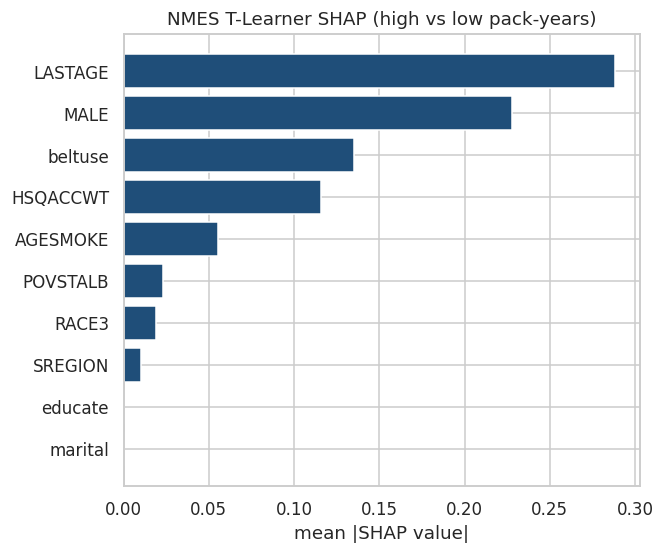

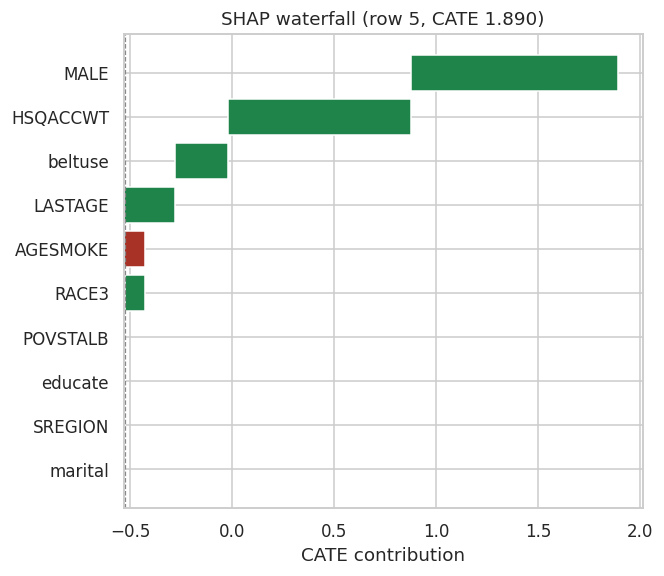

In [14]:
exp_t.plot_importance(title="NMES T-Learner SHAP (high vs low pack-years)")
plt.show()
exp_t.plot_waterfall(row=int(np.argmax(np.abs(exp_t.predictions))))
plt.show()


## Summary and Conclusions

This notebook demonstrated meta-learners for continuous treatments (**Part A**: synthetic $D$ with known CADR; **Part B**: NMES **`nmes_data`** with `TOTALEXP`, `packyears`, and covariates from **`this tutorial (`data/nmes_data.csv`)`**). Key takeaways:

- **CADR**: For continuous treatment $D$, a natural target is $\tau(d,x) = \frac{\partial}{\partial d}\mathbb{E}[Y(d)|X=x]$, the marginal effect of dose at $d$ given $x$, estimated on a **dose grid** by **`r_learner_continuous()`**.
- **Native continuous meta-learners**: **`SLearner`**, **`TLearner`**, **`XLearner`**, **`RLearner`**, and **`DRLearner`** accept **`treatment_type = "continuous"`** and numeric **`treatment`** (e.g. `packyears`); estimands differ (quartile contrast, median split, Robinson, continuous DR, etc.—see **Details** in each function’s documentation).
- **R-Learner for continuous (grid)**: Cross-fit outcome and treatment (E[D|X]) models, form residuals, then use local linear regression with kernel weights over a dose grid to estimate $\tau(d,x)$ (or population averages).
- **Bandwidth**: Silverman-type rule used here; in practice choose via cross-validation. Local linear regression reduces boundary bias vs. kernel averaging.
- **Heterogeneity**: Stratifying by covariates (e.g., X1) shows how dose-response differs across subgroups; the R-Learner output can be used for subgroup-specific curves.
- **SHAP**: Because `r_learner_continuous()` returns a dose $\times$ unit surface, we explain **variation in** $\hat{\tau}(d_{\mathrm{ref}}, x)$ across units by permutation SHAP on a **ranger surrogate** of those slopes at a fixed reference dose. Interpret as attribution for **model-estimated** heterogeneity, not as causal Shapley effects for the true DGP.
- **Diagnostics**: Overlap (distribution of $D$ and $E[D|X]$), balance (SMD before/after stabilized IPTW), and CATE calibration (predicted vs residualized outcome by quintile) support the validity of dose-response estimates.
- **Decision framework**: Use the R-Learner for debiased, flexible dose-response estimation; consider GRF or causal BART when a single forest or Bayesian approach is preferred. Always check overlap and balance.
- **NMES (Part B)**: Continuous **`r_learner_continuous()`** curve for **`packyears`**; **S/T/X/R/DR** with **`treatment_type = "continuous"`** on raw **`packyears`** (native API); **binary** median-split **S/T/X/R/DR** for discrete ATE and **SHAP**; **`LinearDML` / `SparseLinearDML` / `CausalForestDML`** on the same subsample with **ATE**, **holdout RMSE** for $\hat{\mathbb{E}}[Y\mid X]$, **Spearman** agreement of predicted CATE, and **permutation SHAP** for $\hat{\theta}(X)$; **`learner="rf"`** in nuisances where used. Interpret under **unconfoundedness**; use survey weights properly in real reporting.

For a **full dose–response surface** on a grid, use **`r_learner_continuous()`** or methods such as **GRF**. For a **single vector** of heterogeneous effects with continuous $D$, use **`treatment_type = "continuous"`** on the standard meta-learners and read each learner’s estimand in the package help. Validate bandwidth and overlap in $D$ given $X$; use SHAP on an explicit target (here, surrogate predictions at $d_{\mathrm{ref}}$ or binary $\hat{\tau}(X)$) when reporting interpretability.

## References

1. Nie & Wager (2021). *Biometrika*: Quasi-oracle estimation (R-Learner theory)  
2. Kennedy et al. (2017). *JASA*: Nonparametric causal effects of continuous treatments  
3. Athey & Wager (2019). *arXiv*: Generalized random forests  
4. Chernozhukov et al. (2018). *Econometrica*: Double/debiased ML  
5. Imai, K., & van Dyk, D. A. (2004). Causal inference with general treatment regimes. *Journal of the American Statistical Association*, 99(467), 854–866. (NMES / continuous treatment)
